# Лабораторная работа № 3
## Подготовка выборок, кросс-валидация и подбор гиперпараметров метода ближайших соседей

**Цель.** Изучить способы подготовки обучающей и тестовой выборок и подбора гиперпараметра $K$ для классификатора ближайших соседей.

**Задание.** Подготовить данные для классификации, обучить модель с заданным $K$, подобрать $K$ полным и случайным поиском с двумя стратегиями кросс-валидации и сравнить модели по метрикам на тестовой выборке.

Материалы курса

- [Задание лабораторной работы](https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO__KNN)
- [Метод ближайших соседей](https://nbviewer.org/github/ugapanyuk/courses_current/blob/main/notebooks/knn/knn.ipynb)
- [Метрики качества](https://nbviewer.org/github/ugapanyuk/courses_current/blob/main/notebooks/metrics/metrics.ipynb)
- [Кросс-валидация и подбор гиперпараметров](https://nbviewer.org/github/ugapanyuk/courses_current/blob/main/notebooks/crossval/crossval.ipynb)

## 1. Загрузка библиотек и данных

Задача состоит в определении вида пингвина по его измерениям и полу. Одна строка файла `penguins.csv` соответствует одной птице в наборе Palmer Penguins. Целевой столбец `species` содержит три класса — Adelie, Chinstrap и Gentoo.

Для запуска ячеек нужны ядро Python и библиотеки `pandas`, `matplotlib` и `scikit-learn`.

Данные опубликованы Allison M. Horst, Alison P. Hill и Kristen B. Gorman. Лицензия CC0. [Описание датасета](https://allisonhorst.github.io/palmerpenguins/) · [Исходный CSV](https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv)

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    StratifiedShuffleSplit,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_PATH = Path('penguins.csv')
if not DATA_PATH.is_file():
    DATA_PATH = Path('lab3') / DATA_PATH
if not DATA_PATH.is_file():
    DATA_PATH = Path('labs_ml') / DATA_PATH

data = pd.read_csv(DATA_PATH)
print(f'Размер набора данных — {data.shape[0]} строк и {data.shape[1]} столбцов.')
display(data.head())

Размер набора данных — 344 строк и 8 столбцов.


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## 2. Анализ и подготовка данных

Для классификации используются длина и глубина клюва, длина ласта, масса тела и пол птицы. Проверим типы данных, пропуски и распределение целевой переменной.

In [2]:
numeric_features = [
    'bill_length_mm',
    'bill_depth_mm',
    'flipper_length_mm',
    'body_mass_g',
]
categorical_features = ['sex']
target = 'species'

summary = pd.DataFrame({
    'Тип данных': data.dtypes.astype(str),
    'Пропусков': data.isna().sum(),
    'Доля пропусков, %': data.isna().mean().mul(100).round(2),
})
display(summary)
print(f'Полных дубликатов — {data.duplicated().sum()}.')

,Тип данных,Пропусков,"Доля пропусков, %"
species,object,0,0.00
island,object,0,0.00
bill_length_mm,float64,2,0.58
bill_depth_mm,float64,2,0.58
flipper_length_mm,float64,2,0.58
body_mass_g,float64,2,0.58
sex,object,11,3.20
year,int64,0,0.00


Полных дубликатов — 0.


In [3]:
X = data[numeric_features + categorical_features]
y = data[target]
class_counts = y.value_counts().sort_index()
display(pd.DataFrame({
    'Число наблюдений': class_counts,
    'Доля, %': class_counts.div(len(y)).mul(100).round(2),
}))

,Число наблюдений,"Доля, %"
species,,
Adelie,152,44.19
Chinstrap,68,19.77
Gentoo,124,36.05


У каждого числового признака по два пропуска, у `sex` — одиннадцать. Целевая переменная заполнена. В числовых столбцах пропуски заполняются медианой, в `sex` — самым частым значением. Для `sex` применяется one-hot кодирование. У числовых признаков разные единицы измерения и разброс, поэтому перед вычислением евклидова расстояния используется `StandardScaler`.

Преобразования входят в `Pipeline`. На каждой итерации кросс-валидации медианы, мода, категории и параметры масштабирования вычисляются по обучающей части разбиения. Те же параметры применяются к его валидационной части.

In [4]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
])

## 3. Разбиение на обучающую и тестовую выборки

Выделим 20% наблюдений методом `train_test_split`. Параметр `stratify=y` сохраняет примерно одинаковые доли каждого вида в обеих выборках. Обучающая выборка используется для подбора $K$, тестовая — для итоговой оценки качества.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f'Обучающая выборка — {len(X_train)}, тестовая — {len(X_test)}.')
display(pd.DataFrame({
    'Обучающая': y_train.value_counts(),
    'Тестовая': y_test.value_counts(),
}).sort_index())

Обучающая выборка — 275, тестовая — 69.


,Обучающая,Тестовая
species,,
Adelie,122,30
Chinstrap,54,14
Gentoo,99,25


## 4. Исходная модель $k$ ближайших соседей

Прогноз — самый частый класс среди $K$ ближайших обучающих объектов. Для исходной модели зададим $K=5$, евклидово расстояние и одинаковый вес для каждого соседа.

Сравним долю верных ответов (accuracy), precision, recall и F1. В метриках с пометкой macro сначала вычисляется значение для каждого класса, затем берётся среднее с одинаковым весом для всех видов. Для подбора $K$ используется F1-macro, поскольку Chinstrap встречается реже остальных видов.

In [6]:
BASELINE_K = 5
baseline = Pipeline([
    ('preprocessing', preprocessor),
    ('knn', KNeighborsClassifier(n_neighbors=BASELINE_K, metric='euclidean', weights='uniform')),
])
baseline.fit(X_train, y_train)
print(f'Исходная модель обучена с K = {BASELINE_K}.')

Исходная модель обучена с K = 5.


## 5. Подбор $K$ и кросс-валидация

Оба поиска выполняются для каждой стратегии кросс-валидации.

- **StratifiedKFold.** Обучающая выборка делится на пять частей с близкими долями классов. Каждая часть один раз служит валидационной.
- **StratifiedShuffleSplit.** Выполняются пять случайных стратифицированных разбиений 80/20. Валидационные части разных разбиений могут пересекаться.

`GridSearchCV` перебирает все нечётные $K$ от 1 до 31. `RandomizedSearchCV` выбирает 8 различных значений из той же сетки. Для каждого кандидата сравнивается средний F1-macro по пяти разбиениям. Основной результат подбора — модель полного поиска со `StratifiedKFold`, поскольку здесь оценена вся сетка, а каждая строка обучающей выборки участвует в валидации ровно один раз.

In [7]:
strategies = {
    'StratifiedKFold': StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    'StratifiedShuffleSplit': StratifiedShuffleSplit(
        n_splits=5, test_size=0.2, random_state=SEED
    ),
}
param_grid = {'knn__n_neighbors': list(range(1, 32, 2))}
searches = {}
cv_rows = []

for strategy_name, cv in strategies.items():
    candidates = [
        GridSearchCV(baseline, param_grid, scoring='f1_macro', cv=cv),
        RandomizedSearchCV(
            baseline, param_grid, n_iter=8, scoring='f1_macro', cv=cv, random_state=SEED
        ),
    ]
    for search in candidates:
        search.fit(X_train, y_train)
        search_name = type(search).__name__
        searches[(search_name, strategy_name)] = search
        cv_rows.append({
            'Поиск': search_name,
            'Стратегия': strategy_name,
            'Проверено K': len(search.cv_results_['params']),
            'Лучшее K': search.best_params_['knn__n_neighbors'],
            'F1-macro (CV)': search.best_score_,
            'Ст. откл. (CV)': search.cv_results_['std_test_score'][search.best_index_],
        })

cv_results = pd.DataFrame(cv_rows)
display(cv_results.round(4))

,Поиск,Стратегия,Проверено K,Лучшее K,F1-macro (CV),Ст. откл. (CV)
0,GridSearchCV,StratifiedKFold,16,3,0.9924,0.0151
1,RandomizedSearchCV,StratifiedKFold,8,3,0.9924,0.0151
2,GridSearchCV,StratifiedShuffleSplit,16,1,0.9922,0.0100
3,RandomizedSearchCV,StratifiedShuffleSplit,8,1,0.9922,0.0100


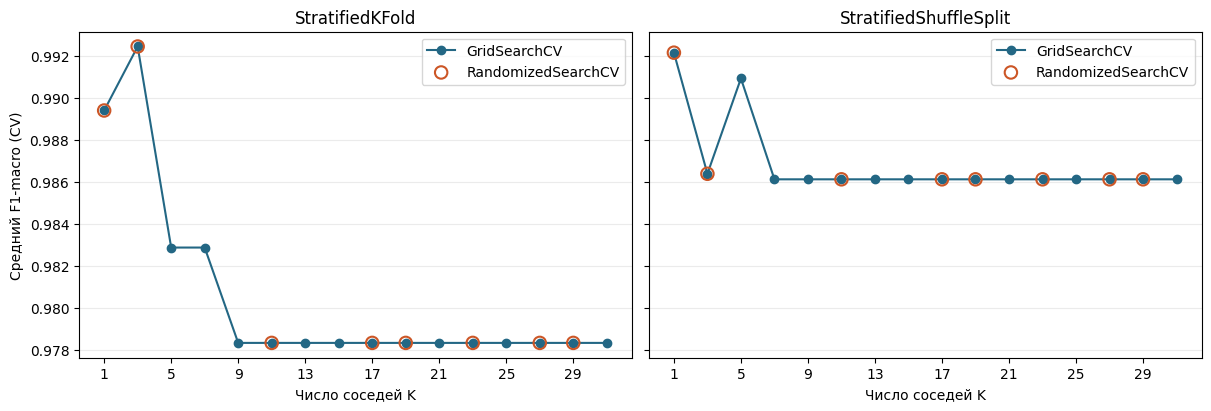

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout='constrained')

for ax, strategy_name in zip(axes, strategies):
    grid_search = searches[('GridSearchCV', strategy_name)]
    random_search = searches[('RandomizedSearchCV', strategy_name)]
    grid_scores = pd.DataFrame(grid_search.cv_results_).sort_values('param_knn__n_neighbors')
    random_scores = pd.DataFrame(random_search.cv_results_)

    ax.plot(
        grid_scores['param_knn__n_neighbors'], grid_scores['mean_test_score'],
        marker='o', color='#236784', label='GridSearchCV'
    )
    ax.scatter(
        random_scores['param_knn__n_neighbors'], random_scores['mean_test_score'],
        s=80, facecolors='none', edgecolors='#cc5626', linewidths=1.5,
        zorder=3, label='RandomizedSearchCV'
    )
    ax.set(title=strategy_name, xlabel='Число соседей K', xticks=range(1, 32, 4))
    ax.grid(axis='y', alpha=0.25)
    ax.legend(loc='upper right')

axes[0].set_ylabel('Средний F1-macro (CV)')
plt.show()

## 6. Сравнение моделей на тестовой выборке

После поиска лучший конвейер для каждого сочетания метода и стратегии заново обучается на всей обучающей выборке (`refit=True` по умолчанию). Сравним прогнозы исходной модели и лучших моделей поиска на одних и тех же тестовых наблюдениях.

In [9]:
models = {('Исходная модель', '—'): baseline}
models.update({name: search.best_estimator_ for name, search in searches.items()})
predictions = {}
test_rows = []

for (model_name, strategy_name), model in models.items():
    predicted = model.predict(X_test)
    predictions[(model_name, strategy_name)] = predicted
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, predicted, average='macro', zero_division=0
    )
    test_rows.append({
        'Модель': model_name,
        'Стратегия': strategy_name,
        'K': model.get_params()['knn__n_neighbors'],
        'Accuracy': accuracy_score(y_test, predicted),
        'Precision-macro': precision,
        'Recall-macro': recall,
        'F1-macro': f1,
    })

test_results = pd.DataFrame(test_rows)
test_results['Δ F1-macro'] = test_results['F1-macro'] - test_results.loc[0, 'F1-macro']
display(test_results.round(4))

,Модель,Стратегия,K,Accuracy,Precision-macro,Recall-macro,F1-macro,Δ F1-macro
0,Исходная модель,—,5,1.0000,1.0000,1.0000,1.0000,0.0000
1,GridSearchCV,StratifiedKFold,3,1.0000,1.0000,1.0000,1.0000,0.0000
2,RandomizedSearchCV,StratifiedKFold,3,1.0000,1.0000,1.0000,1.0000,0.0000
3,GridSearchCV,StratifiedShuffleSplit,1,0.9855,0.9778,0.9889,0.9829,-0.0171
4,RandomizedSearchCV,StratifiedShuffleSplit,1,0.9855,0.9778,0.9889,0.9829,-0.0171


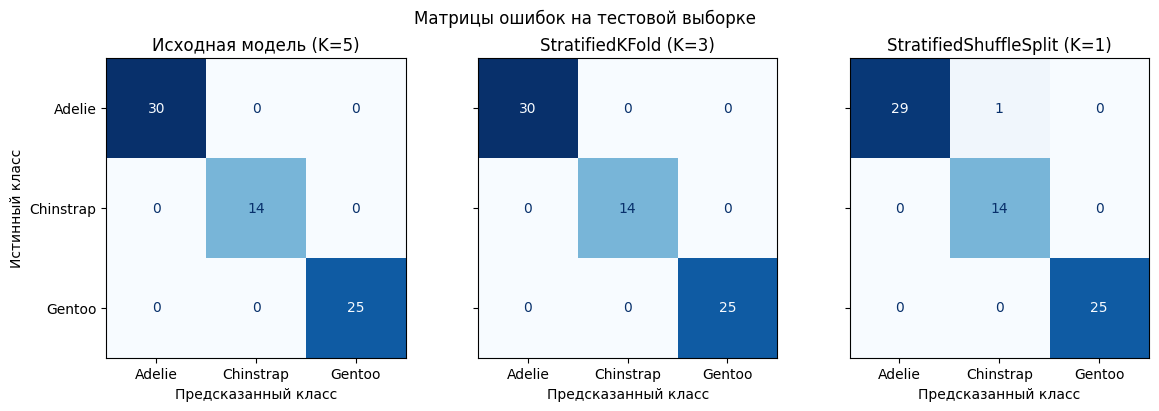

In [10]:
baseline_key = ('Исходная модель', '—')
selected_key = ('GridSearchCV', 'StratifiedKFold')
selected_k = searches[selected_key].best_params_['knn__n_neighbors']
labels = class_counts.index.tolist()

shuffle_key = ('GridSearchCV', 'StratifiedShuffleSplit')
shuffle_k = searches[shuffle_key].best_params_['knn__n_neighbors']
matrix_models = {
    baseline_key: f'Исходная модель (K={BASELINE_K})',
    selected_key: f'StratifiedKFold (K={selected_k})',
    shuffle_key: f'StratifiedShuffleSplit (K={shuffle_k})',
}

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, layout='constrained')
for ax, (key, title) in zip(axes, matrix_models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[key], labels=labels, cmap='Blues', values_format='d',
        colorbar=False, im_kw={'vmin': 0, 'vmax': y_test.value_counts().max()}, ax=ax
    )
    ax.set(title=title, xlabel='Предсказанный класс', ylabel='')

axes[0].set_ylabel('Истинный класс')
fig.suptitle('Матрицы ошибок на тестовой выборке')
plt.show()

## Вывод

1. Набор Palmer Penguins разделён на 275 обучающих и 69 тестовых наблюдений. Заполнение пропусков, кодирование пола и масштабирование числовых признаков выполнялись внутри конвейера.
2. При пятиблочной стратифицированной кросс-валидации оба поиска выбрали $K=3$ со средним F1-macro 0,9924. При пяти случайных стратифицированных разбиениях оба поиска выбрали $K=1$ со средним F1-macro 0,9922. В этом эксперименте восемь случайно выбранных кандидатов дали те же значения $K$, что и полный перебор шестнадцати.
3. На отложенной выборке исходная модель ($K=5$) и модель, выбранная полным поиском со `StratifiedKFold` ($K=3$), верно определили виды всех 69 пингвинов. У обеих accuracy и F1-macro равны 1,0000. Подбор показал, что такое же качество на этой выборке достигается с тремя соседями.
4. Модель с $K=1$ отнесла одного пингвина Adelie к виду Chinstrap. Её accuracy составила 0,9855, а F1-macro — 0,9829.